# Reto: clasificación de 3 escenas (bosque, costa y autopista)

Se usa el dataset local de 3 escenas (`coast`, `forest`, `highway`; 958
imágenes) y se comparan, sobre el mismo split y con las mismas métricas, una CNN
secuencial (base y mejorada), una arquitectura **no secuencial** (DenseNet121
preentrenada en ImageNet con fine-tuning), dos **ViT** —uno entrenado **desde cero** y otro preentrenado en ImageNet con
fine-tuning— (la bala de IA generativa; el enunciado admite «ViT, SWIN u otro») y los
**modelos de machine learning** con descriptores HSV+HOG que hacen de línea base
del curso.

| Grupo | Modelo | Cuaderno | Resultados |
|---|---|---|---|
| CNN | CNN base y CNN mejorada | `ScenesCNN.ipynb` | `resultados/cnn/` |
| DL no secuencial | DenseNet121 preentrenada + fine-tuning | `ScenesDenseNet.ipynb` | `resultados/densenet/` |
| IA generativa | ViT (Vision Transformer) entrenado desde cero | `ScenesViT.ipynb` | `resultados/vit/` |
| IA generativa | ViT-B/16 preentrenado en ImageNet + fine-tuning | `ScenesViTPretrained.ipynb` | `resultados/vit_preentrenado/` |
| Machine learning | Regresión logística, SVM (RBF) y Random Forest | `ScenesClassicML.ipynb` | `resultados/ml/` |

Al entrenar el ViT **desde cero** (sin ImageNet), la comparación con la
DenseNet121 separa *arquitectura* (atención vs convolución) de
*preentrenamiento* (ImageNet vs desde cero), y la comparación con la CNN
mejorada v2 —que también arranca desde cero— aísla la arquitectura. La sección
«El ViT: ¿arquitectura o preentrenamiento?» lee esos números con el McNemar y
los IC 95 % de bootstrap, y «El ViT preentrenado: el efecto de ImageNet»
compara los dos ViT entre sí y el preentrenado con la DenseNet121 (los dos
parten de ImageNet).


## Protocolo

* **Dataset**: 958 imágenes JPG (`coast` 360, `forest` 328, `highway` 270; un
  reparto aproximado de 38/34/28 %), redimensionadas a 128×128 con `INTER_AREA`.
* **Split**: 25 % test y, del 75 % restante, un 15 % para validación (estratificado,
  semilla 20 → ≈ 610 train / 108 validación / 240 test, en `resultados/split.json`). El test no se usa para entrenar ni para early
  stopping, y todos los modelos evalúan exactamente el mismo `test_idx`
  (~240 imágenes).
* **Métricas**: accuracy, precisión/recall/F1 macro y weighted, Cohen's kappa,
  ROC-AUC one-vs-rest, matriz de confusión, IC 95 % por bootstrap (2000
  remuestreos) y test exacto de McNemar.
* **Evidencia**: cada modelo guarda `metrics.json`, `predictions.csv`,
  `classification_report.txt`, `history.csv` (solo modelos con épocas) y el
  modelo entrenado (`model.keras` o `model.joblib`; el ViT desde cero, `model.weights.h5`;
el ViT preentrenado, solo los pesos ajustados en `finetuned.weights.npz`,
porque el modelo completo supera el límite de GitHub).

## Carga de resultados y tabla resumen

Si `resultados/` todavía no tiene métricas (los cuadernos de los modelos no se
han ejecutado), este cuaderno imprime un aviso y las celdas siguientes se
omiten **sin lanzar ningún error**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import common_3scenes as cs

sns.set_theme(style="whitegrid", context="notebook")
comparison_dir = cs.result_dir("comparacion")
comparison_dir.mkdir(parents=True, exist_ok=True)

order = [
    "cnn/base",
    "cnn/mejorada",
    "cnn/mejorada_v2",
    "densenet",
    "vit",
    "vit_preentrenado",
    "ml/logreg",
    "ml/svm",
    "ml/rf",
]
results = cs.load_all_results()
split_meta = cs.load_split()
predictions = {}

if results.empty:
    HAS_RESULTS = False
    print(
        "[aviso] Todavía no hay resultados en resultados/. Ejecuta antes "
        "ScenesCNN.ipynb, ScenesDenseNet.ipynb, ScenesViT.ipynb, "
        "ScenesViTPretrained.ipynb y "
        "ScenesClassicML.ipynb (o "
        "usa nbconvert como indica el README). Este cuaderno termina aquí sin "
        "error: las celdas siguientes solo se omiten."
    )
else:
    HAS_RESULTS = True
    results["order"] = results["folder"].map(
        {folder: index for index, folder in enumerate(order)}
    )
    results = (
        results.sort_values("order", na_position="last")
        .drop(columns="order")
        .reset_index(drop=True)
    )

    interval_rows = []
    for _, row in results.iterrows():
        frame = cs.load_predictions(row["folder"])
        predictions[row["model"]] = frame
        if frame is None:
            accuracy_low, accuracy_high = np.nan, np.nan
        else:
            accuracy_low, accuracy_high = cs.bootstrap_accuracy_ci(
                frame["true_class"], frame["predicted_class"], n_boot=2000
            )
        interval_rows.append(
            {
                "model": row["model"],
                "accuracy_low": accuracy_low,
                "accuracy_high": accuracy_high,
            }
        )
    results = results.merge(pd.DataFrame(interval_rows), on="model")

    summary_columns = [
        "model",
        "family",
        "accuracy",
        "f1_macro",
        "f1_weighted",
        "precision_macro",
        "recall_macro",
        "cohen_kappa",
        "roc_auc_ovr_macro",
        "parameters",
        "training_seconds",
        "inference_ms_per_image",
        "epochs",
    ]
    summary = results[summary_columns].copy()
    summary.to_csv(comparison_dir / "model_summary.csv", index=False)

    display_summary = summary.rename(
        columns={
            "model": "Modelo",
            "family": "Familia",
            "accuracy": "Accuracy",
            "f1_macro": "F1 macro",
            "f1_weighted": "F1 weighted",
            "precision_macro": "Precisión macro",
            "recall_macro": "Recall macro",
            "cohen_kappa": "Kappa",
            "roc_auc_ovr_macro": "AUC OVR",
            "parameters": "Parámetros",
            "training_seconds": "Entrenamiento (s)",
            "inference_ms_per_image": "Inferencia (ms/img)",
            "epochs": "Épocas",
        }
    )
    display_summary["Familia"] = display_summary["Familia"].replace(
        {"DL (non-sequential)": "DL (no secuencial)"}
    )
    display_summary["Parámetros"] = display_summary["Parámetros"].map(
        lambda value: "—" if pd.isna(value) else f"{int(value):,}"
    )
    display_summary["Entrenamiento (s)"] = display_summary["Entrenamiento (s)"].map(
        lambda value: "—" if pd.isna(value) else f"{value:,.0f}"
    )
    display_summary["Inferencia (ms/img)"] = display_summary["Inferencia (ms/img)"].map(
        lambda value: "—" if pd.isna(value) else f"{value:.1f}"
    )
    display_summary["Épocas"] = display_summary["Épocas"].map(
        lambda value: "—" if pd.isna(value) else f"{int(value)}"
    )

    print(
        f"[ok] {len(results)} modelos cargados de resultados/ | "
        f"test común: {split_meta.get('n_test', 'n/d')} imágenes"
    )
display_summary.round(4) if HAS_RESULTS else None

[ok] 9 modelos cargados de resultados/ | test común: 240 imágenes


,Modelo,Familia,Accuracy,F1 macro,F1 weighted,Precisión macro,Recall macro,Kappa,AUC OVR,Parámetros,Entrenamiento (s),Inferencia (ms/img),Épocas
0,CNN base,CNN,0.9042,0.9012,0.9035,0.9006,0.9025,0.8554,0.9767,"30,611",7,1.2,15
1,CNN mejorada,CNN,0.8708,0.8608,0.8661,0.8916,0.8553,0.8026,0.9668,"305,251",482,5.1,40
2,CNN mejorada v2,CNN,0.8917,0.8850,0.8890,0.9003,0.8806,0.8351,0.9782,"305,251",963,9.9,51
3,DenseNet121,DL (no secuencial),0.9833,0.9836,0.9833,0.9847,0.9828,0.9748,0.9963,"7,040,579",128,15.9,23
4,ViT (desde cero),IA generativa (Transformer),0.8875,0.8855,0.8864,0.8861,0.8873,0.8303,0.9629,"4,855,299","2,345",35.1,51
5,ViT preentrenado (ImageNet),IA generativa (Transformer),0.9750,0.9757,0.9749,0.9748,0.9774,0.9623,0.9980,"85,800,963","1,212",120.9,12
6,Regresión logística,machine learning,0.9417,0.9391,0.9408,0.9450,0.9362,0.9116,0.9836,—,0,0.0,—
7,SVM (RBF),machine learning,0.9542,0.9526,0.9537,0.9579,0.9497,0.9306,0.9883,—,0,0.4,—
8,Random Forest,machine learning,0.9333,0.9300,0.9323,0.9355,0.9276,0.8990,0.9874,—,2,0.1,—


## Figura 1: accuracy con IC 95 %

Barras de accuracy en el test común con el intervalo de confianza al 95 % de
cada modelo (bootstrap con 2000 remuestreos sobre sus `predictions.csv`). Con
~240 imágenes de test, los intervalos son necesariamente anchos: hay que leer
cada barra junto a su bigote.

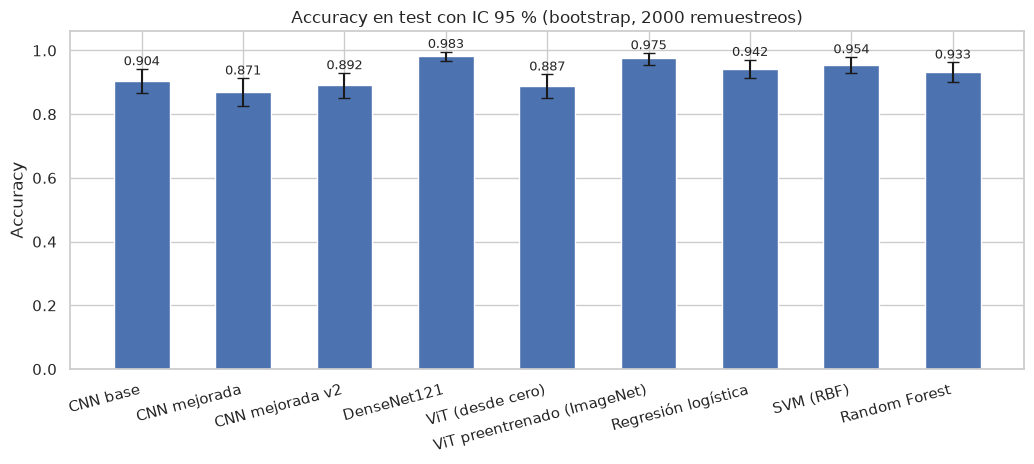

In [2]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: figura omitida.")
else:
    fig, ax = plt.subplots(figsize=(10.5, 4.8))
    positions = np.arange(len(results))
    ax.bar(
        positions,
        results["accuracy"],
        0.55,
        yerr=[
            results["accuracy"] - results["accuracy_low"],
            results["accuracy_high"] - results["accuracy"],
        ],
        capsize=4,
    )
    for position, (_, row) in enumerate(results.iterrows()):
        ax.text(
            position,
            row["accuracy_high"] + 0.012,
            f"{row['accuracy']:.3f}",
            ha="center",
            fontsize=9,
        )
    ax.set_xticks(positions, results["model"], rotation=15, ha="right")
    ax.set_ylim(0, 1.06)
    ax.set_ylabel("Accuracy")
    ax.set_title("Accuracy en test con IC 95 % (bootstrap, 2000 remuestreos)")
    fig.tight_layout()
    fig.savefig(comparison_dir / "barras_accuracy_ic95.png", dpi=150, bbox_inches="tight")
    plt.show()

## Figura 2: matrices de confusión

Una matriz de confusión normalizada por fila para cada modelo (de nuevo el
mismo test): dónde se concentra el error y qué clases se confunden entre sí.

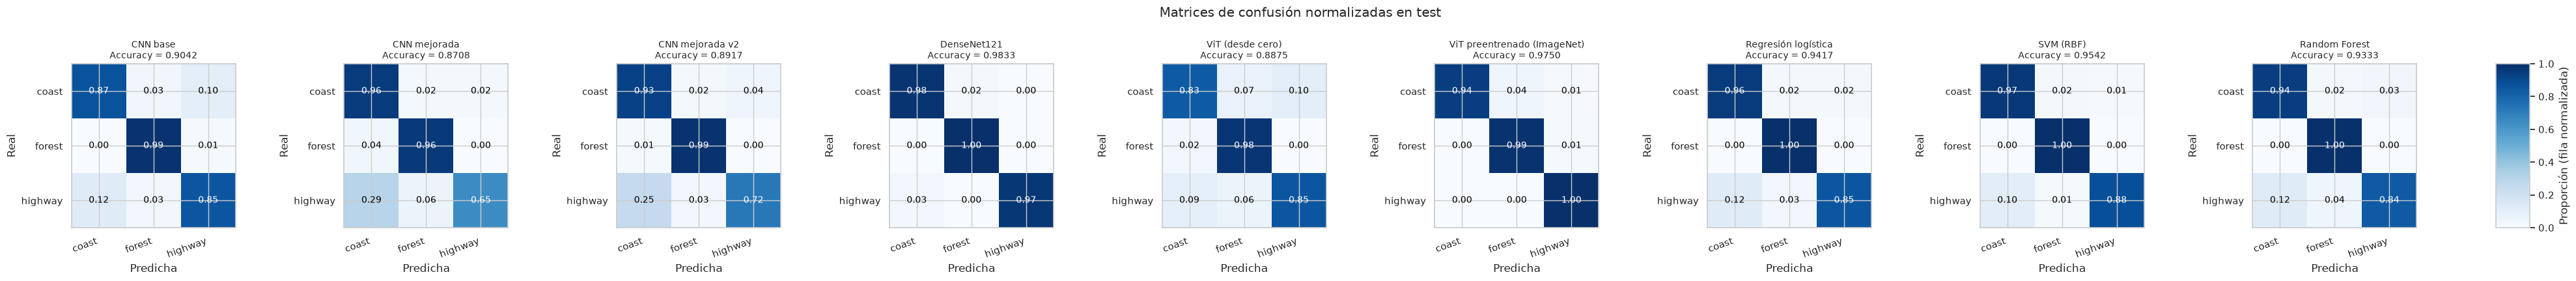

In [3]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: figura omitida.")
else:
    fig, axes = plt.subplots(1, len(results), figsize=(4.8 * len(results), 4.2))
    for ax, (_, row) in zip(np.atleast_1d(axes), results.iterrows()):
        metrics = cs.load_metrics(row["folder"])
        matrix = np.asarray(metrics["confusion_matrix"], dtype=float)
        matrix = matrix / matrix.sum(axis=1, keepdims=True)
        image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(len(cs.CLASSES)), cs.CLASSES, rotation=20, ha="right")
        ax.set_yticks(range(len(cs.CLASSES)), cs.CLASSES)
        for row_index in range(len(cs.CLASSES)):
            for column_index in range(len(cs.CLASSES)):
                value = matrix[row_index, column_index]
                ax.text(
                    column_index,
                    row_index,
                    f"{value:.2f}",
                    ha="center",
                    va="center",
                    color="white" if value > 0.5 else "black",
                    fontsize=10,
                )
        ax.set_title(f"{row['model']}\nAccuracy = {row['accuracy']:.4f}", fontsize=10)
        ax.set_xlabel("Predicha")
        ax.set_ylabel("Real")

    fig.subplots_adjust(left=0.06, right=0.90, bottom=0.22, top=0.82, wspace=0.50)
    colorbar_ax = fig.add_axes([0.925, 0.22, 0.012, 0.60])
    fig.colorbar(image, cax=colorbar_ax, label="Proporción (fila normalizada)")
    fig.suptitle("Matrices de confusión normalizadas en test", y=1.03)
    fig.savefig(comparison_dir / "matrices_confusion.png", dpi=150, bbox_inches="tight")
    plt.show()

## Figura 3: curvas de aprendizaje

Accuracy y pérdida (train y validación) por época de los modelos con épocas.
Los modelos de **machine learning no tienen curvas** (no hay épocas ni
`history.csv`), así que se omiten y se anota la omisión.

[nota] Sin curvas de aprendizaje (modelos sin épocas): Regresión logística, SVM (RBF), Random Forest


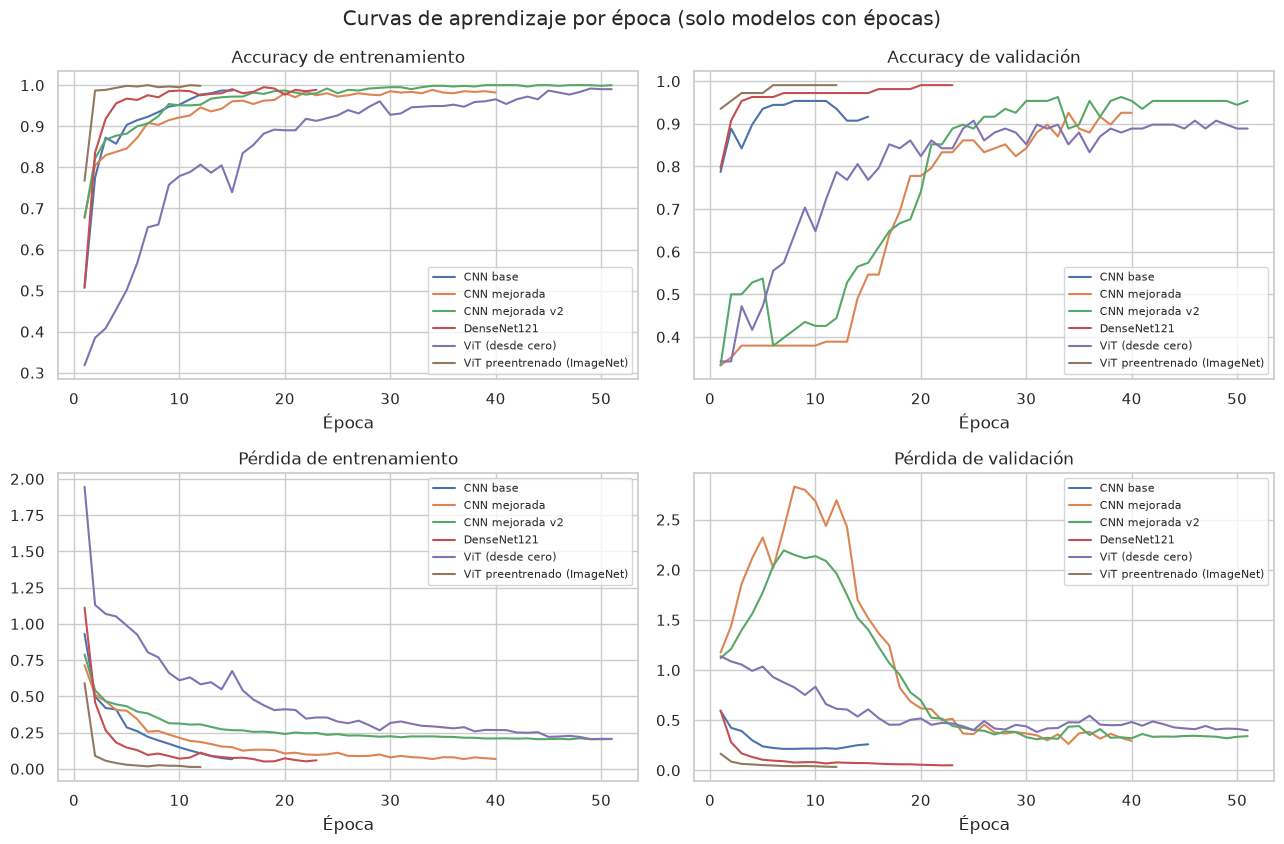

In [4]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: figura omitida.")
else:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8.6))
    curves = [
        ("accuracy", "Accuracy de entrenamiento", axes[0, 0]),
        ("val_accuracy", "Accuracy de validación", axes[0, 1]),
        ("loss", "Pérdida de entrenamiento", axes[1, 0]),
        ("val_loss", "Pérdida de validación", axes[1, 1]),
    ]

    with_curves = []
    for _, row in results.iterrows():
        history = cs.load_history(row["folder"])
        if history is None:
            continue
        with_curves.append(row["model"])
        for column, _, ax in curves:
            ax.plot(history.index, history[column], label=row["model"])

    for column, title, ax in curves:
        ax.set_xlabel("Época")
        ax.set_title(title)
        ax.legend(fontsize=8)

    without_curves = [name for name in results["model"] if name not in with_curves]
    if without_curves:
        print(
            "[nota] Sin curvas de aprendizaje (modelos sin épocas): "
            + ", ".join(without_curves)
        )
    fig.suptitle("Curvas de aprendizaje por época (solo modelos con épocas)")
    fig.tight_layout()
    fig.savefig(comparison_dir / "curvas_aprendizaje.png", dpi=150, bbox_inches="tight")
    plt.show()

## Figura 4: F1 por clase

Heatmap del F1-score de cada clase para cada modelo: revela si algún modelo
paga su accuracy global en una clase concreta.

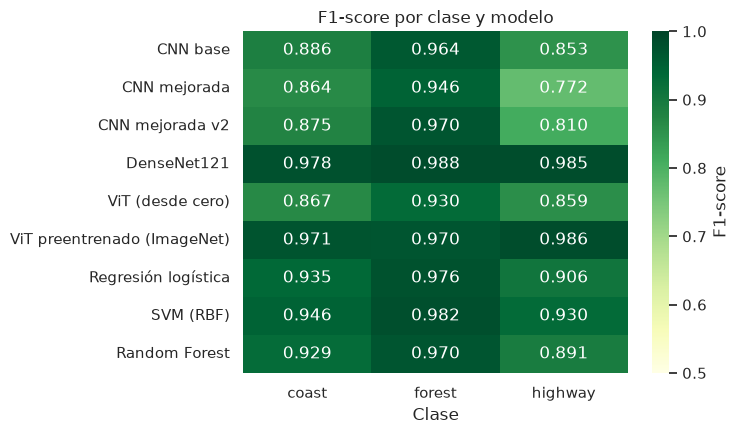

In [5]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: figura omitida.")
else:
    f1_columns = [f"f1_{class_name}" for class_name in cs.CLASSES]
    f1_matrix = results.set_index("model")[f1_columns]
    f1_matrix.columns = cs.CLASSES

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    sns.heatmap(
        f1_matrix,
        annot=True,
        fmt=".3f",
        cmap="YlGn",
        vmin=0.5,
        vmax=1,
        ax=ax,
        cbar_kws={"label": "F1-score"},
    )
    ax.set_title("F1-score por clase y modelo")
    ax.set_xlabel("Clase")
    ax.set_ylabel("")
    fig.tight_layout()
    fig.savefig(comparison_dir / "heatmap_f1_por_clase.png", dpi=150, bbox_inches="tight")
    plt.show()
    f1_matrix.round(4)

## Validación estadística: McNemar

Test exacto de McNemar sobre las predicciones emparejadas del mismo test para
las comparaciones que pide el reto: base vs mejorada, mejorada vs DenseNet121,
base vs DenseNet121, el ViT contra la CNN mejorada v2 y contra la DenseNet121,
y el mejor modelo de machine learning contra el mejor modelo de aprendizaje
profundo.
La tabla se guarda también como `resultados/comparacion/mcnemar_pvalues.csv`
(junto a `model_summary.csv`).


In [6]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: tabla omitida.")
else:
    def model_of(folder):
        return results.loc[results["folder"] == folder, "model"].iloc[0]

    best_ml_row = (
        results[results["folder"].str.startswith("ml/")]
        .sort_values("accuracy", ascending=False)
        .iloc[0]
    )
    best_dl_row = (
        results[~results["folder"].str.startswith("ml/")]
        .sort_values("accuracy", ascending=False)
        .iloc[0]
    )

    comparison_pairs = [
        ("cnn/base", "cnn/mejorada"),
        ("cnn/mejorada", "densenet"),
        ("cnn/base", "densenet"),
        ("cnn/mejorada_v2", "cnn/base"),
        ("cnn/mejorada_v2", "cnn/mejorada"),
        ("cnn/mejorada_v2", "densenet"),
        ("vit", "cnn/mejorada_v2"),
        ("vit", "densenet"),
        ("vit_preentrenado", "vit"),
        ("vit_preentrenado", "densenet"),
        (best_ml_row["folder"], best_dl_row["folder"]),
    ]
    available = set(results["folder"])
    comparison_pairs = [
        (folder_a, folder_b)
        for folder_a, folder_b in comparison_pairs
        if folder_a in available and folder_b in available
    ]

    rows = []
    for folder_a, folder_b in comparison_pairs:
        name_a, name_b = model_of(folder_a), model_of(folder_b)
        frame_a = predictions.get(name_a)
        frame_b = predictions.get(name_b)
        if frame_a is None or frame_b is None:
            p_value = np.nan
        else:
            p_value = cs.mcnemar_pvalue(
                frame_a["true_class"],
                frame_a["predicted_class"],
                frame_b["predicted_class"],
            )
        rows.append({"modelo_a": name_a, "modelo_b": name_b, "p_valor": p_value})

    mcnemar_table = pd.DataFrame(rows)
    mcnemar_table.to_csv(
        comparison_dir / "mcnemar_pvalues.csv",
        float_format="%.4f",
        index=False,
    )
    print(f"Mejor modelo clásico: {best_ml_row['model']} ({best_ml_row['accuracy']:.2%}).")
    print(f"Mejor modelo de deep learning: {best_dl_row['model']} ({best_dl_row['accuracy']:.2%}).")
mcnemar_table.round(4) if HAS_RESULTS else None

Mejor modelo clásico: SVM (RBF) (95.42%).
Mejor modelo de deep learning: DenseNet121 (98.33%).


,modelo_a,modelo_b,p_valor
0,CNN base,CNN mejorada,0.2005
1,CNN mejorada,DenseNet121,0.0000
2,CNN base,DenseNet121,0.0001
3,CNN mejorada v2,CNN base,0.7011
4,CNN mejorada v2,CNN mejorada,0.2668
5,CNN mejorada v2,DenseNet121,0.0000
6,ViT (desde cero),CNN mejorada v2,1.0000
7,ViT (desde cero),DenseNet121,0.0000
8,ViT preentrenado (ImageNet),ViT (desde cero),0.0001
9,ViT preentrenado (ImageNet),DenseNet121,0.6875


## El ViT: ¿arquitectura o preentrenamiento?

El ViT de `resultados/vit/` (`ScenesViT.ipynb`) se entrena **desde cero** sobre
el split congelado, sin pesos de ImageNet: atención **global** sobre todos los
parches y una arquitectura **plana**. Eso permite separar dos efectos que en el
reto van siempre juntos:

* **Arquitectura**: CNN mejorada v2 vs ViT compara convolución y atención con
  el mismo punto de partida (las dos se entrenan desde cero, sin ImageNet).
* **Preentrenamiento**: DenseNet121 vs ViT suma al cambio de arquitectura el
  efecto de arrancar de filtros ya aprendidos en ImageNet.

Las tres preguntas de la entrega se responden en la celda siguiente **leyendo
los números** de `resultados/` (accuracy, IC 95 % por bootstrap y el McNemar
de la sección anterior):

1. ¿Es el Transformer competitivo con DenseNet121?
2. ¿Cuánto del hueco es arquitectura y cuánto preentrenamiento?
3. ¿Es la diferencia significativa según McNemar o queda dentro del IC?

Si `resultados/vit/` todavía no existe, la celda imprime un `[aviso]` y el
cuaderno continúa sin error.


In [7]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: análisis del ViT omitido.")
else:
    vit_rows = results[results["folder"] == "vit"]
    densenet_rows = results[results["folder"] == "densenet"]
    if vit_rows.empty:
        print(
            "[aviso] No hay resultados del ViT en resultados/vit/ (ejecuta antes "
            "ScenesViT.ipynb): el análisis del Transformer se omite y el "
            "cuaderno continúa sin error."
        )
    elif densenet_rows.empty:
        print(
            "[aviso] Faltan los resultados de la DenseNet121 (ejecuta antes "
            "ScenesDenseNet.ipynb): análisis del ViT omitido."
        )
    else:
        vit_row = vit_rows.iloc[0]
        densenet_row = densenet_rows.iloc[0]
        best_cnn_folder = (
            "cnn/mejorada_v2" if "cnn/mejorada_v2" in set(results["folder"]) else "cnn/mejorada"
        )
        best_cnn_row = results[results["folder"] == best_cnn_folder].iloc[0]
        improved_acc = best_cnn_row["accuracy"]
        gap_densenet = 100 * (densenet_row["accuracy"] - vit_row["accuracy"])
        gap_architecture = 100 * (vit_row["accuracy"] - improved_acc)
        intervals_overlap = (
            vit_row["accuracy_high"] >= densenet_row["accuracy_low"]
            and densenet_row["accuracy_high"] >= vit_row["accuracy_low"]
        )
        n_total = split_meta.get("n_total", "n/d")

        def pvalue_of(folder_a, folder_b):
            # McNemar is symmetric: accept the pair in either order
            names = {model_of(folder_a), model_of(folder_b)}
            matched = mcnemar_table[
                mcnemar_table["modelo_a"].isin(names)
                & mcnemar_table["modelo_b"].isin(names)
                & (mcnemar_table["modelo_a"] != mcnemar_table["modelo_b"])
            ]
            return np.nan if matched.empty else matched["p_valor"].iloc[0]

        p_densenet_vit = pvalue_of("densenet", "vit")
        p_improved_vit = pvalue_of(best_cnn_folder, "vit")

        print("El ViT frente a la CNN mejorada y a DenseNet121 (números de resultados/)")
        print("=" * 78)
        print(
            f"1. ¿Competitivo? ViT (desde cero): {vit_row['accuracy']:.2%} "
            f"(IC 95 % {vit_row['accuracy_low']:.2%}–{vit_row['accuracy_high']:.2%}); "
            f"DenseNet121 (ImageNet): {densenet_row['accuracy']:.2%} "
            f"(IC 95 % {densenet_row['accuracy_low']:.2%}–{densenet_row['accuracy_high']:.2%}). "
            f"Hueco: {gap_densenet:+.1f} puntos."
        )
        print(
            f"2. Arquitectura o preentrenamiento: frente a la {best_cnn_row['model']} "
            f"({improved_acc:.2%}, también desde cero), el ViT "
            f"({vit_row['accuracy']:.2%}) aporta {gap_architecture:+.1f} puntos "
            f"atribuibles a la arquitectura (atención global vs convolución). El hueco "
            f"restante hasta DenseNet121 ({gap_densenet:+.1f} puntos) no es solo "
            f"arquitectura: mezcla atención y el preentrenamiento en ImageNet "
            f"(~1,2 M de imágenes frente a las {n_total} del reto), así que no se "
            f"puede atribuir en solitario a ninguno de los dos efectos."
        )
        if pd.isna(p_densenet_vit):
            print("3. Significancia: no disponible (faltan predicciones).")
        else:
            verdict = (
                "diferencia estadísticamente significativa"
                if p_densenet_vit < 0.05
                else "diferencia dentro del ruido del muestreo"
            )
            print(
                f"3. Significancia: McNemar DenseNet121 vs ViT: "
                f"p = {p_densenet_vit:.4f} → {verdict}."
            )
            if not pd.isna(p_improved_vit):
                verdict_improved = (
                    "significativa"
                    if p_improved_vit < 0.05
                    else "no significativa"
                )
                print(
                    f"   {best_cnn_row['model']} vs ViT: p = {p_improved_vit:.4f} → "
                    f"diferencia {verdict_improved}."
                )
            print(
                "   En el bootstrap, los IC 95 % de los dos modelos "
                + ("solapan." if intervals_overlap else "no solapan.")
            )


El ViT frente a la CNN mejorada y a DenseNet121 (números de resultados/)
1. ¿Competitivo? ViT (desde cero): 88.75% (IC 95 % 85.00%–92.50%); DenseNet121 (ImageNet): 98.33% (IC 95 % 96.67%–99.58%). Hueco: +9.6 puntos.
2. Arquitectura o preentrenamiento: frente a la CNN mejorada v2 (89.17%, también desde cero), el ViT (88.75%) aporta -0.4 puntos atribuibles a la arquitectura (atención global vs convolución). El hueco restante hasta DenseNet121 (+9.6 puntos) no es solo arquitectura: mezcla atención y el preentrenamiento en ImageNet (~1,2 M de imágenes frente a las 958 del reto), así que no se puede atribuir en solitario a ninguno de los dos efectos.
3. Significancia: McNemar DenseNet121 vs ViT: p = 0.0000 → diferencia estadísticamente significativa.
   CNN mejorada v2 vs ViT: p = 1.0000 → diferencia no significativa.
   En el bootstrap, los IC 95 % de los dos modelos no solapan.


## El ViT preentrenado: el efecto de ImageNet

`resultados/vit_preentrenado/` (`ScenesViTPretrained.ipynb`) es un ViT-B/16
de `keras-hub` preentrenado en ImageNet y ajustado en dos fases, igual que la
DenseNet121 (cabeza con el backbone congelado y después fine-tuning de los
últimos bloques). Con él se cierran las dos comparaciones que el ViT desde
cero deja abiertas:

* **ViT desde cero vs ViT preentrenado**: misma familia de arquitectura, solo
  cambia el punto de partida → cuánto vale el preentrenamiento para un
  Transformer.
* **ViT preentrenado vs DenseNet121**: los dos parten de ImageNet y se ajustan
  igual → atención frente a convolución a igualdad de preentrenamiento.

La celda lee los números de `resultados/` y el McNemar de la sección de
validación; si falta alguno de los modelos imprime un `[aviso]` y sigue.

In [8]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: análisis del ViT preentrenado omitido.")
elif not {"vit", "vit_preentrenado", "densenet"} <= set(results["folder"]):
    print(
        "[aviso] Faltan resultados de vit/, vit_preentrenado/ o densenet/ (ejecuta "
        "antes ScenesViT.ipynb, ScenesViTPretrained.ipynb y ScenesDenseNet.ipynb): "
        "análisis omitido."
    )
else:
    def row_of(folder):
        return results[results["folder"] == folder].iloc[0]

    def verdict_of(p_value):
        if pd.isna(p_value):
            return "no disponible"
        return "significativa" if p_value < 0.05 else "dentro del ruido"

    scratch, pretrained, densenet = row_of("vit"), row_of("vit_preentrenado"), row_of("densenet")
    p_pretrained_scratch = pvalue_of("vit_preentrenado", "vit")
    p_pretrained_densenet = pvalue_of("vit_preentrenado", "densenet")
    gap_pretraining = 100 * (pretrained["accuracy"] - scratch["accuracy"])
    gap_attention = 100 * (pretrained["accuracy"] - densenet["accuracy"])

    print("El ViT preentrenado (números de resultados/)")
    print("=" * 78)
    for row in (scratch, pretrained, densenet):
        print(
            f"   {row['model']}: {row['accuracy']:.2%} "
            f"(IC 95 % {row['accuracy_low']:.2%}–{row['accuracy_high']:.2%}), "
            f"{int(row['parameters']):,} parámetros, {row['training_seconds']:.0f} s"
        )
    print(
        f"1. Preentrenamiento (mismo tipo de modelo): ViT preentrenado − ViT desde "
        f"cero = {gap_pretraining:+.1f} puntos; McNemar p = {p_pretrained_scratch:.4f} "
        f"→ diferencia {verdict_of(p_pretrained_scratch)}."
    )
    print(
        f"2. Atención vs convolución (los dos con ImageNet): ViT preentrenado − "
        f"DenseNet121 = {gap_attention:+.1f} puntos; McNemar p = "
        f"{p_pretrained_densenet:.4f} → diferencia {verdict_of(p_pretrained_densenet)}."
    )

El ViT preentrenado (números de resultados/)
   ViT (desde cero): 88.75% (IC 95 % 85.00%–92.50%), 4,855,299 parámetros, 2345 s
   ViT preentrenado (ImageNet): 97.50% (IC 95 % 95.42%–99.17%), 85,800,963 parámetros, 1212 s
   DenseNet121: 98.33% (IC 95 % 96.67%–99.58%), 7,040,579 parámetros, 128 s
1. Preentrenamiento (mismo tipo de modelo): ViT preentrenado − ViT desde cero = +8.8 puntos; McNemar p = 0.0001 → diferencia significativa.
2. Atención vs convolución (los dos con ImageNet): ViT preentrenado − DenseNet121 = -0.8 puntos; McNemar p = 0.6875 → diferencia dentro del ruido.


## Conclusiones

Las conclusiones se **generan en la celda siguiente** a partir de los
artefactos de `resultados/` (`metrics.json`, `predictions.csv`,
`split.json`): ninguna cifra de este reto está escrita a mano, de modo que
si un modelo se reentrena, las conclusiones se recalculan solas. El esquema es
el que pide el enunciado: quién gana, si la diferencia es estadísticamente
significativa o ruido del intervalo de confianza, cuánto aporta cada cambio
(más filtros, BatchNorm, augmentación, GAP, conectividad densa + transferencia
de ImageNet, atención global desde cero) y qué limitación impone el
dataset.

In [9]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: no hay conclusiones que generar todavía.")
else:
    ranked = results.sort_values("accuracy", ascending=False).reset_index(drop=True)
    best = ranked.iloc[0]
    second = ranked.iloc[1]
    best_ml_row = (
        results[results["folder"].str.startswith("ml/")]
        .sort_values("accuracy", ascending=False)
        .iloc[0]
    )
    best_dl_row = (
        results[~results["folder"].str.startswith("ml/")]
        .sort_values("accuracy", ascending=False)
        .iloc[0]
    )

    def accuracy_of(folder):
        return results.loc[results["folder"] == folder, "accuracy"].iloc[0]

    def format_count(value):
        if value is None or pd.isna(value):
            return "n/d"
        return f"{int(value):,}"

    best_cnn_folder = (
        "cnn/mejorada_v2" if "cnn/mejorada_v2" in set(results["folder"]) else "cnn/mejorada"
    )
    best_cnn_row = results[results["folder"] == best_cnn_folder].iloc[0]
    delta_improved = 100 * (accuracy_of(best_cnn_folder) - accuracy_of("cnn/base"))
    delta_densenet = 100 * (accuracy_of("densenet") - accuracy_of(best_cnn_folder))
    delta_transfer = 100 * (accuracy_of("densenet") - accuracy_of("cnn/base"))
    delta_ml_dl = 100 * (best_dl_row["accuracy"] - best_ml_row["accuracy"])
    ci_widths = 100 * (results["accuracy_high"] - results["accuracy_low"])
    n_total = split_meta.get("n_total", "n/d")
    n_test = split_meta.get("n_test", "n/d")

    if pd.isna(best["accuracy_low"]):
        interval = "IC no disponible"
    else:
        interval = (
            f"IC 95 % {best['accuracy_low']:.2%}–{best['accuracy_high']:.2%}"
        )

    print("Conclusiones (generadas a partir de resultados/)")
    print("=" * 78)
    print(
        f"1. Ganador. {best['model']} es el mejor modelo en test: accuracy "
        f"{best['accuracy']:.2%} ({interval}), F1 macro {best['f1_macro']:.2%}, "
        f"kappa {best['cohen_kappa']:.3f} y {format_count(best['parameters'])} "
        f"parámetros. Le sigue {second['model']} con {second['accuracy']:.2%}."
    )
    print("2. Significancia (test exacto de McNemar, α = 0,05):")
    for _, row in mcnemar_table.iterrows():
        if pd.isna(row["p_valor"]):
            print(
                f"   - {row['modelo_a']} vs {row['modelo_b']}: no disponible "
                "(faltan predicciones)."
            )
        else:
            verdict = (
                "diferencia significativa"
                if row["p_valor"] < 0.05
                else "diferencia dentro del ruido"
            )
            print(
                f"   - {row['modelo_a']} vs {row['modelo_b']}: "
                f"p = {row['p_valor']:.4f} → {verdict}."
            )
    print("3. Contribución de cada cambio (puntos de accuracy sobre el mismo test):")
    print(
        f"   - CNN base → {best_cnn_row['model']} (más filtros, BatchNorm, GAP, Dropout, "
        f"augmentación, class_weight): {delta_improved:+.1f} puntos."
    )
    print(
        f"   - {best_cnn_row['model']} → DenseNet121 (conectividad densa + transferencia de "
        f"ImageNet): {delta_densenet:+.1f} puntos."
    )
    print(
        f"   - CNN base → DenseNet121 (todo lo anterior junto): "
        f"{delta_transfer:+.1f} puntos."
    )
    transformer_folder = "vit"
    if transformer_folder in set(results["folder"]):
        transformer_row = results[results["folder"] == transformer_folder].iloc[0]
        print(
            f"   - {best_cnn_row['model']} → {transformer_row['model']} "
            f"(atención vs convolución, ambas desde cero): "
            f"{100 * (accuracy_of(transformer_folder) - accuracy_of(best_cnn_folder)):+.1f} puntos."
        )
        print(
            f"   - {transformer_row['model']} → DenseNet121 (cambio de arquitectura + "
            f"preentrenamiento de ImageNet): "
            f"{100 * (accuracy_of('densenet') - accuracy_of(transformer_folder)):+.1f} puntos."
        )
    if {"vit", "vit_preentrenado"} <= set(results["folder"]):
        print(
            f"   - ViT desde cero → ViT preentrenado (preentrenamiento de ImageNet, "
            f"mismo tipo de modelo): "
            f"{100 * (accuracy_of('vit_preentrenado') - accuracy_of('vit')):+.1f} puntos."
        )
        print(
            f"   - DenseNet121 → ViT preentrenado (atención vs convolución, ambos con "
            f"ImageNet): "
            f"{100 * (accuracy_of('vit_preentrenado') - accuracy_of('densenet')):+.1f} puntos."
        )
    print(
        f"   - Mejor modelo clásico ({best_ml_row['model']}, "
        f"{best_ml_row['accuracy']:.2%}) vs mejor modelo de deep learning "
        f"({best_dl_row['model']}, {best_dl_row['accuracy']:.2%}): "
        f"{delta_ml_dl:+.1f} puntos."
    )
    print(
        f"4. Limitación del dataset. El dataset tiene {n_total} imágenes en "
        f"{len(cs.CLASSES)} clases y solo {n_test} imágenes de test. El IC 95 % "
        f"más ancho de la figura 1 mide {ci_widths.max():.1f} puntos "
        f"porcentuales, de modo que diferencias de pocos puntos entre modelos "
        f"quedan dentro del ruido del muestreo: para decidir si son reales hay "
        f"que mirar el McNemar de la sección anterior."
    )
    print(
        f"5. Coste. {best['model']} tardó {best['training_seconds']:.0f} s en "
        f"entrenar y {best['inference_ms_per_image']:.1f} ms/imagen en inferir. "
        f"Los modelos de machine learning no tienen épocas ni un conteo de "
        f"parámetros comparable (así se registra en sus metrics.json) y son la "
        f"referencia de coste bajo."
    )
    def significance(p_value):
        if pd.isna(p_value):
            return "McNemar no disponible"
        verdict = "significativa" if p_value < 0.05 else "dentro del ruido"
        return f"McNemar p = {p_value:.4f}, {verdict}"

    available_folders = set(results["folder"])
    if "vit" in available_folders:
        gap_cnn = 100 * (accuracy_of("vit") - accuracy_of(best_cnn_folder))
        gap_dense = 100 * (accuracy_of("densenet") - accuracy_of("vit"))
        beats_cnn = gap_cnn > 0 and not pd.isna(p_improved_vit) and p_improved_vit < 0.05
        print(
            f"6. IA generativa (Transformer). El ViT entrenado desde cero llega a "
            f"{100 * accuracy_of('vit'):.2f}% con {split_meta.get('n_train', 'n/d')} "
            f"imágenes de train: {gap_cnn:+.1f} puntos frente a "
            f"{best_cnn_row['model']} ({significance(p_improved_vit)}), así que sin "
            f"preentrenamiento la atención global "
            f"{'supera a' if beats_cnn else 'no supera de forma significativa a'} "
            f"la convolución; y "
            f"queda {gap_dense:.1f} puntos por debajo de DenseNet121 "
            f"({significance(p_densenet_vit)})."
        )
        if "vit_preentrenado" in available_folders:
            gap_pre = 100 * (accuracy_of("vit_preentrenado") - accuracy_of("vit"))
            gap_att = 100 * (accuracy_of("vit_preentrenado") - accuracy_of("densenet"))
            p_pre = pvalue_of("vit_preentrenado", "vit")
            p_att = pvalue_of("vit_preentrenado", "densenet")
            if p_pre < 0.05 and not p_att < 0.05:
                reading = (
                    "con tan pocos datos, lo que decide es partir de ImageNet, más "
                    "que elegir atención o convolución."
                )
            elif p_att < 0.05:
                reading = (
                    "a igualdad de preentrenamiento la arquitectura sí marca una "
                    f"diferencia, a favor de {'la atención' if gap_att > 0 else 'la convolución'}."
                )
            else:
                reading = "ninguna de las dos diferencias sale del ruido del test."
            print(
                f"   El ViT preentrenado en ImageNet llega a "
                f"{100 * accuracy_of('vit_preentrenado'):.2f}%: el preentrenamiento "
                f"aporta {gap_pre:+.1f} puntos al mismo tipo de modelo "
                f"({significance(p_pre)}). Frente a "
                f"DenseNet121, a igualdad de preentrenamiento, la diferencia es "
                f"{gap_att:+.1f} puntos "
                f"({significance(p_att)}): {reading}"
            )
        print(
            "   El enunciado agrupa el Transformer como «IA generativa», pero "
            "aquí se usa como clasificador discriminativo: lo que comparte "
            "con la IA generativa es la arquitectura de atención."
        )

Conclusiones (generadas a partir de resultados/)
1. Ganador. DenseNet121 es el mejor modelo en test: accuracy 98.33% (IC 95 % 96.67%–99.58%), F1 macro 98.36%, kappa 0.975 y 7,040,579 parámetros. Le sigue ViT preentrenado (ImageNet) con 97.50%.
2. Significancia (test exacto de McNemar, α = 0,05):
   - CNN base vs CNN mejorada: p = 0.2005 → diferencia dentro del ruido.
   - CNN mejorada vs DenseNet121: p = 0.0000 → diferencia significativa.
   - CNN base vs DenseNet121: p = 0.0001 → diferencia significativa.
   - CNN mejorada v2 vs CNN base: p = 0.7011 → diferencia dentro del ruido.
   - CNN mejorada v2 vs CNN mejorada: p = 0.2668 → diferencia dentro del ruido.
   - CNN mejorada v2 vs DenseNet121: p = 0.0000 → diferencia significativa.
   - ViT (desde cero) vs CNN mejorada v2: p = 1.0000 → diferencia dentro del ruido.
   - ViT (desde cero) vs DenseNet121: p = 0.0000 → diferencia significativa.
   - ViT preentrenado (ImageNet) vs ViT (desde cero): p = 0.0001 → diferencia significativa.
  

## Comparación con el machine learning original de la guía 2

Al inicio del curso (`guia-2/reto-5/reto-5.ipynb`) se entrenaron 9 modelos
clásicos sobre este mismo dataset con descriptores de color y textura
(medias y desviaciones de RGB y de HSV y los 13 descriptores de Haralick de la
GLCM). Las cifras de esta sección **se transcriben de las salidas de ese
cuaderno** (no se reentrenan aquí). Ese cuaderno usa el mismo protocolo (25 %
de test, semilla 20, split estratificado, 240 imágenes de test), pero carga las
imágenes en otro orden, así que no se garantiza que sean exactamente las mismas
240 imágenes: la comparación es orientativa y no entra en el McNemar.

**Accuracy en test de la guía 2 con el mejor bloque de características (RGB+HSV+Haralick, 25 descriptores):**

| Modelo (guía 2) | Accuracy CV (5 pliegues) | Accuracy test |
|---|---|---|
| Random Forest | 90.11 % | **90.00 %** |
| MLP | 90.67 % | 89.17 % |
| SVC (RBF) — elegido por CV | **90.81 %** | 88.75 % |
| Regresión logística | 89.70 % | 88.75 % |
| Stacking (KNN + SVC + RF) | 90.25 % | 88.33 % |
| KNN | 86.63 % | 83.33 % |
| Árbol de decisión | 81.20 % | 82.08 % |
| Bayes gaussiano | 80.92 % | 77.50 % |
| K-means (no supervisado, K = 3) | — | 66.39 % (extrínseca) |

La línea base del cuaderno original de la guía 2 (un MLP con solo las medias y
desviaciones de RGB, 6 descriptores) llegaba al **81.25 %**.

**Todos los modelos, ordenados por accuracy en test:**

| Familia | Modelo | Características | Accuracy test |
|---|---|---|---|
| DL no secuencial | DenseNet121 (ImageNet + fine-tuning) | aprendidas | **98.33 %** |
| Transformer | ViT-B/16 preentrenado (ImageNet + fine-tuning) | aprendidas | 97.50 % |
| ML (este reto) | SVM (RBF) | HSV + HOG | 95.42 % |
| ML (este reto) | Regresión logística | HSV + HOG | 94.17 % |
| ML (este reto) | Random Forest | HSV + HOG | 93.33 % |
| CNN | CNN base (cuaderno del profesor) | aprendidas | 90.42 % |
| ML (guía 2) | Random Forest | RGB + HSV + Haralick | 90.00 % |
| CNN | CNN mejorada v2 | aprendidas | 89.17 % |
| Transformer | ViT desde cero | aprendidas | 88.75 % |
| ML (guía 2) | SVC (RBF) | RGB + HSV + Haralick | 88.75 % |
| CNN | CNN mejorada v1 | aprendidas | 87.08 % |
| ML (guía 2) | MLP (línea base) | medias/desv. RGB | 81.25 % |

### Conclusiones de la comparación ML / DL / Transformer

1. **Frente al ML del inicio del curso, el aprendizaje profundo sí mejora.**
   DenseNet121 (98.33 %) supera al mejor modelo de la guía 2 (Random Forest,
   90.00 %; SVC, 88.75 %) por unos 8–10 puntos, y la CNN base del profesor
   (90.42 %) ya lo iguala sin diseñar ninguna característica a mano. Frente a
   la línea base de la guía 2 (81.25 %), la DenseNet121 reduce el error de
   ~19 % a ~2 %.
2. **Las características pesan tanto como el modelo.** El mismo SVM pasa de
   88.75 % (RGB+HSV+Haralick, guía 2) a 95.42 % (HSV+HOG, este reto) solo
   cambiando los descriptores: el HOG captura la estructura de bordes y
   orientaciones (líneas de la carretera, horizonte del mar, textura del
   follaje), que es justo lo que distingue estas escenas. Con HOG, el ML clásico
   supera a todas las redes entrenadas desde cero, incluido el ViT.
3. **Con ~610 imágenes de train, lo que más aporta es el preentrenamiento.**
   Las redes entrenadas desde cero (CNN base, v1, v2 y ViT) quedan entre 87 %
   y 90 %, en la banda del mejor modelo de la guía 2 y por debajo del ML con
   HOG. Los dos modelos que parten de ImageNet son los únicos que superan al
   mejor modelo clásico: DenseNet121 (98.33 %) y el ViT preentrenado (97.50 %),
   aunque frente al SVM con HOG la diferencia de la DenseNet121 no es
   significativa (McNemar p = 0.0654).
4. **El Transformer depende del preentrenamiento más que nadie.** El ViT desde
   cero (88.75 %) empata con la CNN mejorada v2 (89.17 %, McNemar p = 1.0000) y
   con el SVC de la guía 2: sin los sesgos inductivos de la convolución
   (localidad, pesos compartidos) tiene que aprenderlos de 610 imágenes y no
   pasa de ahí. El mismo tipo de modelo preentrenado en ImageNet sube a
   97.50 % (+8.8 puntos, p = 0.0001) y queda empatado con la DenseNet121
   (−0.8 puntos, p = 0.6875): a igualdad de preentrenamiento, atención y
   convolución rinden igual en este dataset, y lo que decide es partir de
   ImageNet.
5. **Coste.** Los modelos clásicos entrenan en menos de 2 s; la DenseNet121
   necesita ~2 min (7 M de parámetros), la CNN v2 ~16 min, el ViT preentrenado
   ~20 min (86 M de parámetros) y el ViT desde cero ~39 min, todos en CPU. Si
   basta con ~95 %, el SVM con HOG es la opción más eficiente; si se busca el
   máximo, la DenseNet121 da lo mismo que el ViT preentrenado con 12 veces
   menos parámetros y 10 veces menos tiempo.


## Notas finales

* Toda la evidencia de esta comparación queda en `resultados/comparacion/`:
  `model_summary.csv`, `mcnemar_pvalues.csv` y las cuatro figuras
  (`barras_accuracy_ic95.png`, `matrices_confusion.png`,
  `curvas_aprendizaje.png`, `heatmap_f1_por_clase.png`).
* Con ~240 imágenes de test, el IC 95 % de la accuracy es intrínsecamente
  ancho; por eso el reto pide además el bootstrap y el McNemar antes de
  declarar un ganador.
* Los descriptores HSV+HOG son la línea base clásica de este reto; la
  comparación con el ML original de la guía 2 (RGB+HSV+Haralick) está en la
  sección «Comparación con el machine learning original de la guía 2».
* La comparación con aprendizaje profundo y con IA generativa queda
  recogida en las conclusiones generadas y en la sección «El ViT: ¿arquitectura
  o preentrenamiento?».